# Cidade Alfa 156+ · Portfólio de Machine Learning

**Regressão · Classificação · Clusterização · Detecção de anomalias** com **317 mil chamados reais**
de zeladoria urbana (dados abertos do SP156, Prefeitura de São Paulo, licença CC0, jan–set/2026).

Projeto do grupo **Data_Drivens** (PBL Data Science · FIAP). A base vem da Fase 4
(exploração e preparação de dados) do app [Cidade Alfa 156+](https://app-alpha-three-46.vercel.app),
que torna o prazo (SLA) dos chamados visível ao cidadão.

| Técnica | Pergunta de negócio | Modelos comparados |
| --- | --- | --- |
| **1. Regressão** | Quantos dias um chamado vai levar para ser resolvido? | baseline · Regressão Linear · Gradient Boosting |
| **2. Classificação** | Este chamado vai estourar o prazo? (previsão na abertura) | baseline · Regressão Logística · Gradient Boosting |
| **3. Clusterização** | Que perfis de atendimento as subprefeituras têm? Onde ficam os focos de buraco? | K-Means · DBSCAN |
| **4. Anomalias** | Que dias fogem do normal? Que coordenadas são suspeitas? | z-score robusto · Isolation Forest |

**Princípios usados em todo o notebook**
1. **Sem vazamento de dados:** os modelos só usam o que se sabe **na abertura** do chamado.
2. **Comparação com baseline:** todo modelo é medido contra uma regra simples.
3. **Validação honesta:** na classificação, treino de jan–jun e teste de jul–set (como em produção).

In [1]:
import os, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import HistGradientBoostingRegressor, HistGradientBoostingClassifier, IsolationForest
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.inspection import permutation_importance
from sklearn import metrics
warnings.filterwarnings('ignore', category=FutureWarning)

SEMENTE = 156
COR = {'serie': '#2a78d6', 'texto': '#0b0b0b', 'texto2': '#52514e', 'mudo': '#898781',
       'grade': '#e1e0d9', 'eixo': '#c3c2b7', 'fundo': '#fcfcfb', 'alerta': '#a8400f', 'claro': '#6da7ec'}
CATEGORICAS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']  # ordem fixa validada
plt.rcParams.update({
    'figure.facecolor': COR['fundo'], 'axes.facecolor': COR['fundo'], 'savefig.facecolor': COR['fundo'],
    'font.size': 11, 'axes.titlesize': 14, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': COR['grade'],
    'axes.axisbelow': True, 'legend.frameon': False, 'axes.edgecolor': COR['eixo'],
    'xtick.color': COR['texto2'], 'ytick.color': COR['texto'], 'axes.labelcolor': COR['texto2'],
})
br = lambda t: t.translate(str.maketrans(',.', '.,'))                    # 52,142.5 -> 52.142,5
fmt = lambda v, d=1: br(f'{v:,.{d}f}')

FIGURAS = Path('figuras'); FIGURAS.mkdir(exist_ok=True)
METRICAS = {'sklearn': sklearn.__version__}
def salvar(fig, nome):
    """Mostra a figura no notebook e grava em figuras/ (usadas na página /modelos do app)."""
    fig.text(0.01, -0.02, 'Fonte: dados abertos SP156 (Prefeitura de São Paulo, CC0), jan–set/2026.',
             fontsize=8.5, color=COR['mudo'], va='top')
    fig.savefig(FIGURAS / nome, dpi=160, bbox_inches='tight')
    plt.show()
print('scikit-learn', sklearn.__version__)

scikit-learn 1.9.1


## Os dados

Base preparada na Fase 4 (camada Ouro): os 6 serviços de zeladoria do app, sem duplicatas
prováveis e sem cancelados. **Sem endereço** e com coordenadas arredondadas a 3 casas (~100 m),
como a pseudonimização prevista na arquitetura do projeto.

In [2]:
REPO = 'https://raw.githubusercontent.com/peixotojeff/cidade-alfa-156-main/main/portfolio/dados'
local = Path(os.environ.get('PORTFOLIO_DADOS', 'dados'))
fonte = local if (local / 'sp156_modelagem.parquet').exists() else REPO
base = pd.read_parquet(f'{fonte}/sp156_modelagem.parquet')
volume = pd.read_csv(f'{fonte}/volume_diario.csv', parse_dates=['data'], index_col='data')

NOMES = {'via': 'Buraco na via', 'residuos': 'Entulho', 'bueiro': 'Bueiro',
         'calcada': 'Guias e sarjetas', 'arvore': 'Árvore', 'veiculo': 'Veículo abandonado'}
METRICAS['linhas'] = len(base)
print(f'{len(base):,} chamados · {base.shape[1]} colunas'.replace(',', '.'))
base.head()

317.482 chamados · 21 colunas


,data_abertura,mes,dia_semana,dia_mes,semana_do_mes,flag_fim_de_semana,servico,prefeitura,canal,lat,...,apoios_proxy,carga_7d,sla_dias,status,flag_finalizada,tempo_atendimento_dias,estouro_sla_dias,flag_cumpriu_sla,faixa_atendimento,data_corte
0,2026-01-01,1,3,1,1,0,bueiro,M'Boi Mirim,CRM,-23.689,...,0,0,7,finalizada,1,20.0,13,0.0,Atraso crítico,2026-08-06
1,2026-01-01,1,3,1,1,0,veiculo,Aricanduva-Formosa-Carrão,PORTAL,-23.540,...,0,0,30,finalizada,1,55.0,25,0.0,Atraso leve,2026-08-06
2,2026-01-01,1,3,1,1,0,veiculo,São Miguel,MOBILE,-23.489,...,0,0,30,finalizada,1,20.0,-10,1.0,No prazo,2026-08-06
3,2026-01-01,1,3,1,1,0,veiculo,Vila Prudente,MOBILE,-23.593,...,0,0,30,finalizada,1,125.0,95,0.0,Atraso crítico,2026-08-06
4,2026-01-01,1,3,1,1,0,arvore,Vila Mariana,MOBILE,-23.578,...,0,0,30,finalizada,1,35.0,5,0.0,Atraso leve,2026-08-06


### Entradas permitidas × desfecho

| Usado como entrada (conhecido na abertura) | Nunca usado como entrada (desfecho) |
| --- | --- |
| serviço, subprefeitura, canal, coordenada | `tempo_atendimento_dias`, `estouro_sla_dias` |
| mês, dia da semana, dia do mês, fim de semana | `flag_cumpriu_sla`, `faixa_atendimento`, `status` |
| `carga_7d`: chamados do mesmo serviço na mesma subprefeitura nos 7 dias anteriores | data de finalização |
| `apoios_proxy`: repetições do mesmo problema no mesmo dia e ponto | |
| `sla_dias`: prazo do serviço | |

In [3]:
CAT = ['servico', 'prefeitura', 'canal']
NUM = ['mes', 'dia_semana', 'dia_mes', 'flag_fim_de_semana', 'lat', 'lon', 'apoios_proxy', 'carga_7d', 'sla_dias']
ENTRADAS = CAT + NUM

def preprocessador_linear():
    """One-hot nas categorias; imputação + padronização nas numéricas (modelos lineares)."""
    return ColumnTransformer([
        ('cat', OneHotEncoder(handle_unknown='ignore', min_frequency=50), CAT),
        ('num', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), NUM),
    ])

---
## 1. Regressão — quantos dias o chamado vai levar?

**Alvo:** `tempo_atendimento_dias` dos chamados **finalizados**, modelado em escala logarítmica
(`log1p`), porque a distribuição tem cauda longa: a maioria resolve em poucos dias e poucos levam meses.

**Divisão:** 80% treino / 20% teste, estratificada por serviço.

> ⚠️ **Viés de censura.** Só conhecemos o tempo de quem já foi resolvido. Um chamado aberto em setembro e já
> resolvido é, necessariamente, rápido — e o modelo aprenderia que "mês recente = rápido", o que é falso.
> Para reduzir esse efeito, usamos só chamados com **pelo menos 90 dias de observação** até a data de extração
> da planilha. Na primeira versão, sem esse filtro, o `mês` aparecia como 2ª variável mais importante.

In [4]:
JANELA_DIAS = 90
fin = base[(base['flag_finalizada'] == 1) & (base['data_abertura'] <= base['data_corte'] - pd.Timedelta(days=JANELA_DIAS))].copy()
print(f'{len(fin):,} chamados resolvidos com ≥ {JANELA_DIAS} dias de observação'.replace(',', '.'))
y = np.log1p(fin['tempo_atendimento_dias'])
X_tr, X_te, y_tr, y_te = train_test_split(fin[ENTRADAS], y, test_size=.2, random_state=SEMENTE, stratify=fin['servico'])

# Baseline: mediana (em log) do serviço no treino
mediana_serv = y_tr.groupby(X_tr['servico'], observed=True).median()
pred = {'Baseline (mediana do serviço)': X_te['servico'].map(mediana_serv).astype(float).to_numpy()}

lin = make_pipeline(preprocessador_linear(), LinearRegression()).fit(X_tr, y_tr)
pred['Regressão Linear'] = lin.predict(X_te)

hgb_reg = HistGradientBoostingRegressor(categorical_features='from_dtype', max_iter=400, learning_rate=.08,
                                        early_stopping=True, random_state=SEMENTE).fit(X_tr, y_tr)
pred['Gradient Boosting'] = hgb_reg.predict(X_te)

dias_real = np.expm1(y_te)
tabela = pd.DataFrame({nome: {
    'MAE (dias)': metrics.mean_absolute_error(dias_real, np.expm1(p).clip(0)),
    'Erro mediano (dias)': metrics.median_absolute_error(dias_real, np.expm1(p).clip(0)),
    'R² (escala log)': metrics.r2_score(y_te, p),
} for nome, p in pred.items()}).T
METRICAS['regressao'] = {'modelos': tabela.round(3).reset_index(names='modelo').to_dict('records'),
                         'n_treino': len(X_tr), 'n_teste': len(X_te)}
tabela

144.302 chamados resolvidos com ≥ 90 dias de observação


,MAE (dias),Erro mediano (dias),R² (escala log)
Baseline (mediana do serviço),11.850213,3.000000,0.471829
Regressão Linear,11.774786,2.664460,0.508336
Gradient Boosting,10.048682,2.205243,0.643273


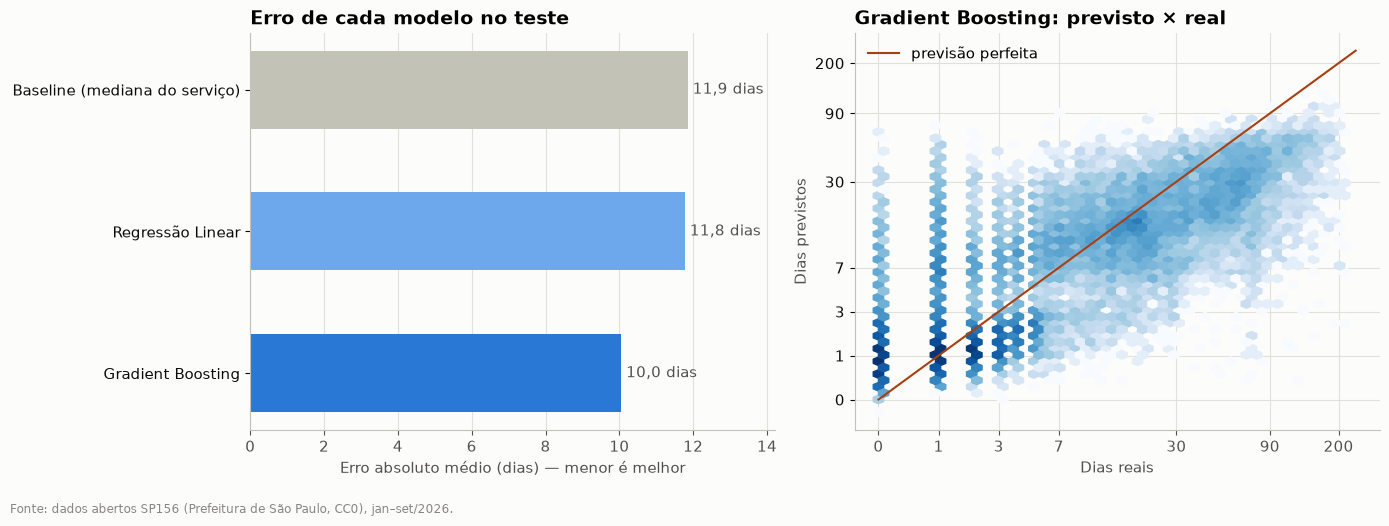

In [5]:
melhor = tabela['MAE (dias)'].idxmin()
ganho = 100 * (1 - tabela.loc[melhor, 'MAE (dias)'] / tabela.loc['Baseline (mediana do serviço)', 'MAE (dias)'])
METRICAS['regressao'].update({'melhor': melhor, 'ganho_mae_pct': round(ganho, 1),
                              'r2_melhor': round(tabela.loc[melhor, 'R² (escala log)'], 3)})

fig, axs = plt.subplots(1, 2, figsize=(14, 5))
cores = [COR['serie'], COR['claro'], COR['eixo']]          # ordem invertida do gráfico: Gradient Boosting, Linear, Baseline
axs[0].barh(tabela.index[::-1], tabela['MAE (dias)'][::-1], color=cores, height=.55)
for i, v in enumerate(tabela['MAE (dias)'][::-1]):
    axs[0].text(v, i, ' ' + fmt(v) + ' dias', va='center', color=COR['texto2'])
axs[0].set_xlabel('Erro absoluto médio (dias) — menor é melhor'); axs[0].grid(axis='y', visible=False); axs[0].margins(x=.2)
axs[0].set_title('Erro de cada modelo no teste')

hb = axs[1].hexbin(y_te, pred['Gradient Boosting'], gridsize=45, cmap='Blues', mincnt=1, bins='log')
lim = [0, float(max(y_te.max(), 5.5))]
axs[1].plot(lim, lim, color=COR['alerta'], lw=1.5, label='previsão perfeita')
ticks = [0, 1, 3, 7, 30, 90, 200]
axs[1].set_xticks(np.log1p(ticks), ticks); axs[1].set_yticks(np.log1p(ticks), ticks)
axs[1].set_xlabel('Dias reais'); axs[1].set_ylabel('Dias previstos'); axs[1].legend(loc='upper left')
axs[1].set_title('Gradient Boosting: previsto × real')
plt.tight_layout(); salvar(fig, '01_regressao.png')

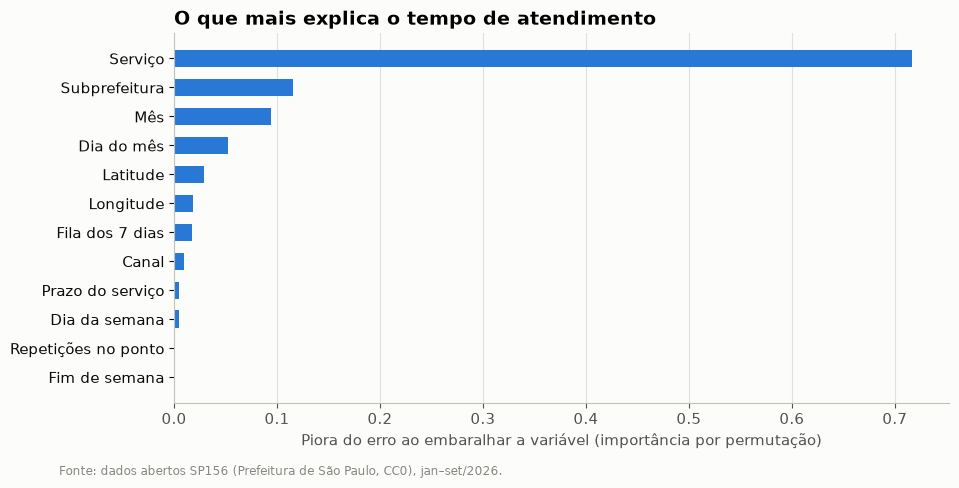

**Leitura:** o **Gradient Boosting** erra em média **10,0 dias**, **15,2% menos** que o baseline (mediana do serviço), com R² de **0,64** na escala log. As variáveis que mais pesam são **serviço, subprefeitura, mês**: além do tipo de serviço, **onde** o chamado está (subprefeitura e coordenada) muda o tempo de resposta. A fila dos 7 dias anteriores pesa pouco.

In [6]:
amostra = X_te.sample(20_000, random_state=SEMENTE)
imp = permutation_importance(hgb_reg, amostra, y_te.loc[amostra.index], n_repeats=3, random_state=SEMENTE,
                             scoring='neg_mean_absolute_error')
importancia_reg = pd.Series(imp.importances_mean, index=ENTRADAS).sort_values()
METRICAS['regressao']['importancia'] = importancia_reg[::-1].head(5).round(4).to_dict()

fig, ax = plt.subplots(figsize=(10, 4.8))
NOMES_VAR = {'servico': 'Serviço', 'prefeitura': 'Subprefeitura', 'canal': 'Canal', 'mes': 'Mês', 'dia_semana': 'Dia da semana',
             'dia_mes': 'Dia do mês', 'flag_fim_de_semana': 'Fim de semana', 'lat': 'Latitude', 'lon': 'Longitude',
             'apoios_proxy': 'Repetições no ponto', 'carga_7d': 'Fila dos 7 dias', 'sla_dias': 'Prazo do serviço'}
ax.barh([NOMES_VAR[i] for i in importancia_reg.index], importancia_reg.to_numpy(), color=COR['serie'], height=.6)
ax.set_xlabel('Piora do erro ao embaralhar a variável (importância por permutação)')
ax.grid(axis='y', visible=False); ax.set_title('O que mais explica o tempo de atendimento')
salvar(fig, '02_regressao_importancia.png')

top = [NOMES_VAR[i].lower() for i in importancia_reg[::-1].index[:3]]
display(Markdown(
    f"**Leitura:** o **{melhor}** erra em média **{fmt(tabela.loc[melhor, 'MAE (dias)'])} dias**, "
    f"**{fmt(ganho)}% menos** que o baseline (mediana do serviço), com R² de **{fmt(tabela.loc[melhor, 'R² (escala log)'], 2)}** "
    f"na escala log. As variáveis que mais pesam são **{', '.join(top)}**: além do tipo de serviço, "
    f"**onde** o chamado está (subprefeitura e coordenada) muda o tempo de resposta. A fila dos 7 dias anteriores pesa pouco."))

---
## 2. Classificação — este chamado vai estourar o prazo?

**Alvo:** `atrasou` = 1 se o chamado passou do prazo (resolvido com atraso ou ainda aberto e vencido),
0 se foi resolvido no prazo. Chamados abertos e ainda dentro do prazo ficam de fora (desfecho desconhecido).

**Validação temporal:** treino com chamados abertos de **janeiro a junho**, teste de **julho a setembro**
— o modelo é avaliado em um período que ele nunca viu, como aconteceria em produção.

**Uso no app:** um alerta de risco no momento da abertura, para a secretaria priorizar.

In [7]:
clf_base = base[base['flag_cumpriu_sla'].notna()].copy()
clf_base['atrasou'] = (clf_base['flag_cumpriu_sla'] == 0).astype(int)
corte = pd.Timestamp('2026-07-01')
tr, te = clf_base[clf_base['data_abertura'] < corte], clf_base[clf_base['data_abertura'] >= corte]
Xc_tr, yc_tr, Xc_te, yc_te = tr[ENTRADAS], tr['atrasou'], te[ENTRADAS], te['atrasou']

proba = {'Baseline (taxa do serviço)': Xc_te['servico'].map(yc_tr.groupby(Xc_tr['servico'], observed=True).mean()).astype(float).to_numpy()}
log_reg = make_pipeline(preprocessador_linear(), LogisticRegression(max_iter=2000)).fit(Xc_tr, yc_tr)
proba['Regressão Logística'] = log_reg.predict_proba(Xc_te)[:, 1]
hgb_clf = HistGradientBoostingClassifier(categorical_features='from_dtype', max_iter=400, learning_rate=.08,
                                         early_stopping=True, random_state=SEMENTE).fit(Xc_tr, yc_tr)
proba['Gradient Boosting'] = hgb_clf.predict_proba(Xc_te)[:, 1]

def resumo(p, y):
    prev = (p >= .5).astype(int)
    top10 = y.to_numpy()[np.argsort(-p)[:len(p) // 10]].mean()      # precisão nos 10% de maior risco
    return {'ROC AUC': metrics.roc_auc_score(y, p), 'PR AUC': metrics.average_precision_score(y, p),
            'Precisão': metrics.precision_score(y, prev, zero_division=0), 'Recall': metrics.recall_score(y, prev),
            'F1': metrics.f1_score(y, prev), 'Precisão no top 10% de risco': top10}
tabela_c = pd.DataFrame({n: resumo(p, yc_te) for n, p in proba.items()}).T
METRICAS['classificacao'] = {'modelos': tabela_c.round(3).reset_index(names='modelo').to_dict('records'),
                             'n_treino': len(tr), 'n_teste': len(te),
                             'taxa_atraso_teste': round(float(yc_te.mean()), 3)}
print(f'Treino: {len(tr):,} · Teste: {len(te):,} · taxa de atraso no teste: {100 * yc_te.mean():.1f}%'.replace(',', '.'))
tabela_c

Treino: 216.299 · Teste: 95.806 · taxa de atraso no teste: 38.2%


,ROC AUC,PR AUC,Precisão,Recall,F1,Precisão no top 10% de risco
Baseline (taxa do serviço),0.774924,0.640609,0.615894,0.724876,0.665955,0.830167
Regressão Logística,0.780790,0.692588,0.619185,0.711678,0.662217,0.825052
Gradient Boosting,0.788636,0.710850,0.613150,0.746844,0.673426,0.863779


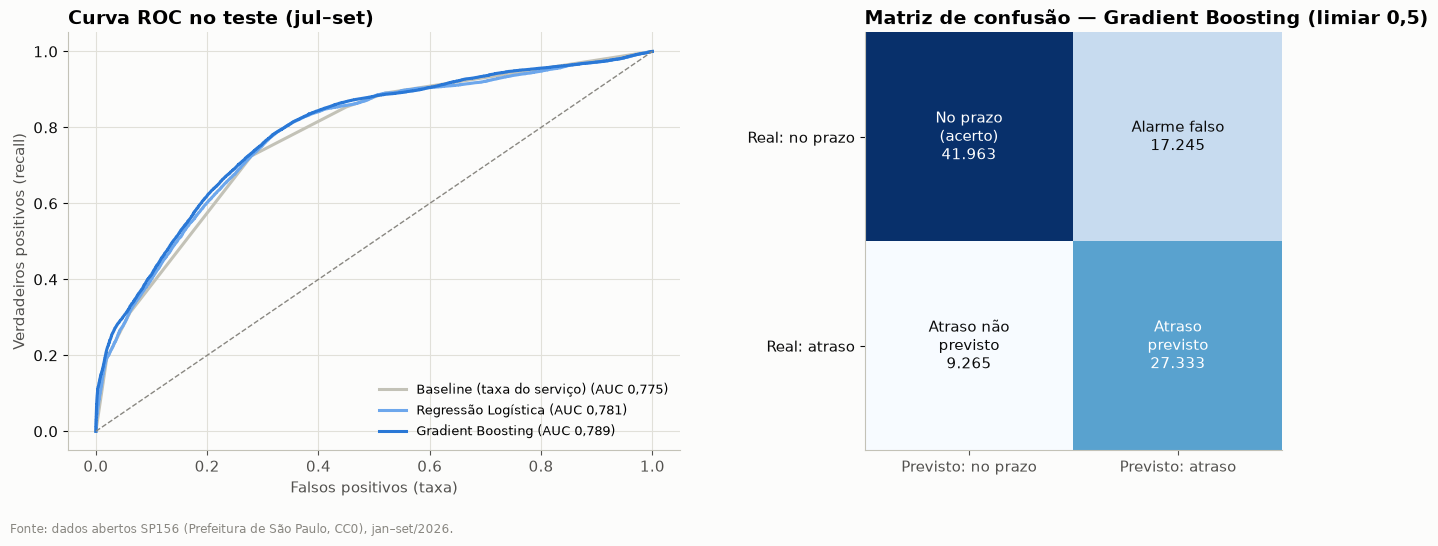

**Leitura:** no período de teste, que o modelo nunca viu, o Gradient Boosting atinge **ROC AUC de 0,789** contra **0,775** do baseline que só olha o tipo de serviço. Entre os **10% de chamados com maior risco**, **86,4%** realmente atrasaram (a taxa geral é 38,2%). O ganho sobre o baseline é **modesto**: a maior parte do risco já está no tipo de serviço (e no seu prazo). O modelo acrescenta local, fila e calendário para **ordenar melhor** os chamados dentro de cada serviço — é esse ranking que viraria um alerta de prioridade na secretaria.

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(14, 5.2))
for (nome, p), cor in zip(proba.items(), [COR['eixo'], COR['claro'], COR['serie']]):
    fpr, tpr, _ = metrics.roc_curve(yc_te, p)
    axs[0].plot(fpr, tpr, color=cor, lw=2.2, label=f"{nome} (AUC {fmt(metrics.roc_auc_score(yc_te, p), 3)})")
axs[0].plot([0, 1], [0, 1], color=COR['mudo'], lw=1, ls='--')
axs[0].set_xlabel('Falsos positivos (taxa)'); axs[0].set_ylabel('Verdadeiros positivos (recall)')
axs[0].legend(loc='lower right', fontsize=9.5); axs[0].set_title('Curva ROC no teste (jul–set)')

cm = metrics.confusion_matrix(yc_te, (proba['Gradient Boosting'] >= .5).astype(int))
axs[1].imshow(cm, cmap='Blues'); axs[1].grid(False)
rot = [['No prazo\n(acerto)', 'Alarme falso'], ['Atraso não\nprevisto', 'Atraso\nprevisto']]
for i in range(2):
    for j in range(2):
        axs[1].text(j, i, f'{rot[i][j]}\n{br(f"{cm[i, j]:,}")}', ha='center', va='center', fontsize=11,
                    color='white' if cm[i, j] > cm.max() / 2 else COR['texto'])
axs[1].set_xticks([0, 1], ['Previsto: no prazo', 'Previsto: atraso']); axs[1].set_yticks([0, 1], ['Real: no prazo', 'Real: atraso'])
axs[1].set_title('Matriz de confusão — Gradient Boosting (limiar 0,5)')
plt.tight_layout(); salvar(fig, '03_classificacao.png')

g = tabela_c.loc['Gradient Boosting']; b = tabela_c.loc['Baseline (taxa do serviço)']
METRICAS['classificacao'].update({'auc_melhor': round(g['ROC AUC'], 3), 'auc_baseline': round(b['ROC AUC'], 3),
                                  'top10_melhor': round(g['Precisão no top 10% de risco'], 3)})
display(Markdown(
    f"**Leitura:** no período de teste, que o modelo nunca viu, o Gradient Boosting atinge **ROC AUC de {fmt(g['ROC AUC'], 3)}** "
    f"contra **{fmt(b['ROC AUC'], 3)}** do baseline que só olha o tipo de serviço. Entre os **10% de chamados com maior risco**, "
    f"**{fmt(100 * g['Precisão no top 10% de risco'])}%** realmente atrasaram (a taxa geral é {fmt(100 * yc_te.mean())}%). "
    f"O ganho sobre o baseline é **modesto**: a maior parte do risco já está no tipo de serviço (e no seu prazo). "
    f"O modelo acrescenta local, fila e calendário para **ordenar melhor** os chamados dentro de cada serviço — "
    f"é esse ranking que viraria um alerta de prioridade na secretaria."))

---
## 3. Clusterização

### 3.1 Perfis de atendimento das subprefeituras (K-Means)

Agrupamos as 32 subprefeituras pelo **desempenho de atendimento**: % resolvido no prazo,
mediana de dias e % de chamados ainda abertos. As variáveis são padronizadas (média 0, desvio 1).

**Escolha de k:** Testamos k de 2 a 6 (com 32 subprefeituras, mais grupos seria sobreajuste). O k = 2 tem a maior silhueta, mas só separa
um pequeno grupo de "lentas" do resto — pouco útil para gestão. Usamos a **melhor silhueta com pelo menos
3 grupos**, e a curva completa fica visível para o leitor julgar. (Testamos também incluir a mistura de
serviços, o uso do celular e a carga: a silhueta caiu para ~0,2 — grupos menos nítidos.)

In [9]:
b2 = base[base['prefeitura'].notna()]
grp = b2.groupby('prefeitura', observed=True)
perfil = pd.DataFrame({
    'pct_no_prazo': 100 * b2[b2['flag_finalizada'] == 1].groupby('prefeitura', observed=True)['flag_cumpriu_sla'].mean(),
    'mediana_dias': b2[b2['flag_finalizada'] == 1].groupby('prefeitura', observed=True)['tempo_atendimento_dias'].median(),
    'pct_abertos': 100 * (1 - grp['flag_finalizada'].mean()),
    'pct_mobile': 100 * grp['canal'].apply(lambda s: (s == 'MOBILE').mean()),
    'repeticoes_por_100': 100 * grp['apoios_proxy'].mean(),
    'carga_media': grp['carga_7d'].mean(),
})
perfil = perfil.dropna()
VARS_CLUSTER = ['pct_no_prazo', 'mediana_dias', 'pct_abertos']          # desempenho de atendimento
Z = StandardScaler().fit_transform(perfil[VARS_CLUSTER])

ks = range(2, 7)          # até 6 grupos: ~5 subprefeituras por grupo; mais que isso seria sobreajuste com 32 pontos
silh = []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=SEMENTE).fit(Z)
    silh.append(metrics.silhouette_score(Z, km.labels_))
k_otimo = max((k for k in ks if k >= 3), key=lambda k: silh[k - 2])   # melhor silhueta com >= 3 grupos
km = KMeans(n_clusters=k_otimo, n_init=20, random_state=SEMENTE).fit(Z)
perfil['cluster'] = km.labels_
METRICAS['clusterizacao'] = {'k': k_otimo, 'silhueta': round(silh[k_otimo - 2], 3), 'n_subprefeituras': len(perfil),
                             'silhueta_por_k': {int(k): round(s, 3) for k, s in zip(ks, silh)}}
print(f'k escolhido: {k_otimo} (silhueta {silh[k_otimo - 2]:.3f}; k=2 teria {silh[0]:.3f})')

k escolhido: 3 (silhueta 0.313; k=2 teria 0.424)


In [10]:
# Descrição automática de cada grupo: as variáveis que mais se afastam da média geral
# Grupos ordenados do melhor ao pior desempenho e nomeados pelo próprio resultado
resumo_cl = perfil.groupby('cluster').mean().sort_values('pct_no_prazo', ascending=False)
nomes = {3: ['Ágeis', 'Intermediárias', 'Lentas'], 4: ['Ágeis', 'Estáveis', 'Pressionadas', 'Sobrecarregadas']}
NOME_GRUPO = dict(zip(resumo_cl.index, nomes.get(len(resumo_cl), [f'Grupo {i + 1}' for i in range(len(resumo_cl))])))
perfil['grupo'] = perfil['cluster'].map(NOME_GRUPO)
grupos = pd.DataFrame({
    'grupo': [NOME_GRUPO[c] for c in resumo_cl.index],
    'subprefeituras': perfil.groupby('cluster').size().reindex(resumo_cl.index),
    '% no prazo': resumo_cl['pct_no_prazo'], 'mediana (dias)': resumo_cl['mediana_dias'],
    '% abertos': resumo_cl['pct_abertos'], '% celular': resumo_cl['pct_mobile'],
    'carga média (7 dias)': resumo_cl['carga_media'],
    'membros': [', '.join(sorted(perfil.index[perfil['cluster'] == c])) for c in resumo_cl.index],
}).set_index('grupo')
METRICAS['clusterizacao']['grupos'] = grupos.round(1).reset_index().to_dict('records')
grupos

,subprefeituras,% no prazo,mediana (dias),% abertos,% celular,carga média (7 dias),membros
grupo,,,,,,,
Ágeis,13,79.452979,2.307692,16.789149,36.858415,66.535109,"Aricanduva-Formosa-Carrão, Capela do Socorro, ..."
Intermediárias,15,75.757854,2.466667,24.871338,37.888998,75.418201,"Campo Limpo, Casa Verde-Limão-Cachoeirinha, Ci..."
Lentas,4,64.939974,7.250000,25.998195,40.014195,74.938346,"Butantã, Lapa, Pinheiros, Vila Mariana"


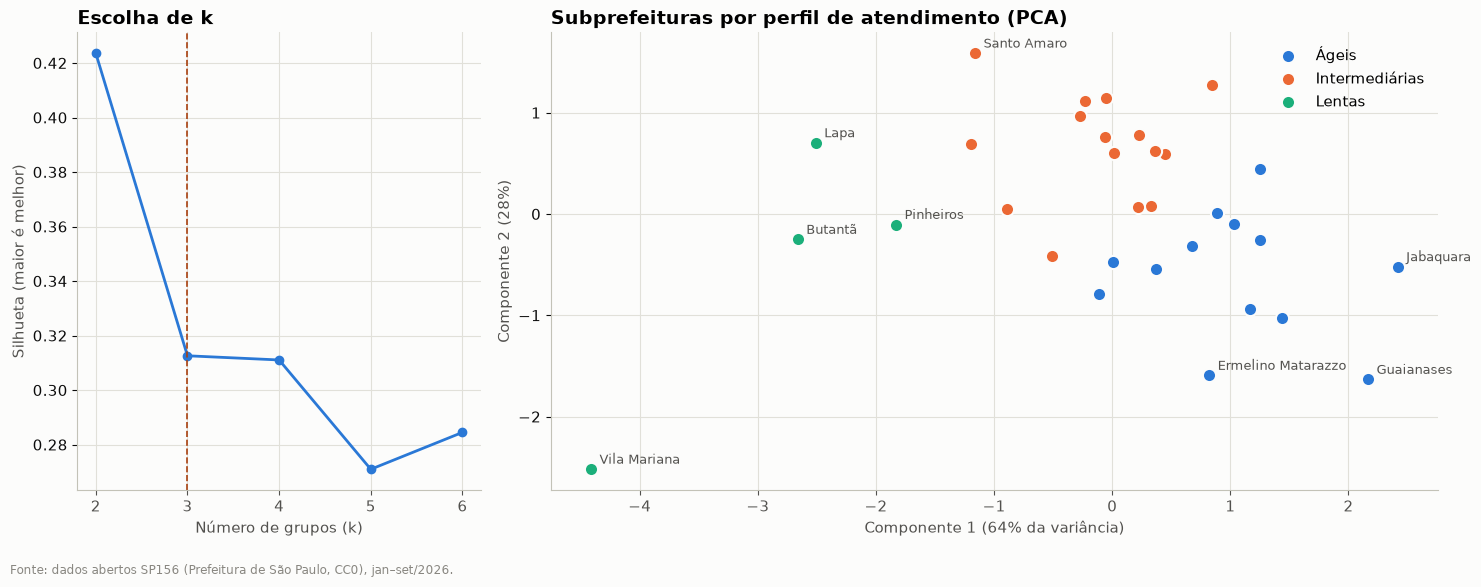

**Leitura:** com silhueta de **0,31**, os grupos são: **Ágeis** (13: 79,5% no prazo, mediana de 2,3 dias); **Intermediárias** (15: 75,8% no prazo, mediana de 2,5 dias); **Lentas** (4: 64,9% no prazo, mediana de 7,2 dias). Isso permite metas e reforço de equipe **por perfil**, em vez de uma meta única para a cidade.

In [11]:
pca = PCA(n_components=2, random_state=SEMENTE).fit(Z)
P = pca.transform(Z)
fig, axs = plt.subplots(1, 2, figsize=(15, 5.6), gridspec_kw={'width_ratios': [1, 2.2]})
axs[0].plot(list(ks), silh, marker='o', color=COR['serie'], lw=2)
axs[0].axvline(k_otimo, color=COR['alerta'], ls='--', lw=1.2)
axs[0].set_xlabel('Número de grupos (k)'); axs[0].set_ylabel('Silhueta (maior é melhor)')
axs[0].set_title('Escolha de k')
for i, c in enumerate(resumo_cl.index):
    m = perfil['cluster'].to_numpy() == c
    axs[1].scatter(P[m, 0], P[m, 1], s=90, color=CATEGORICAS[i], edgecolor=COR['fundo'], linewidth=1.5, label=NOME_GRUPO[c])
# Rótulos só no grupo de pior desempenho e nos extremos (a lista completa está na tabela acima)
pior = resumo_cl.index[-1]
for (x, yv), nome, c in zip(P, perfil.index, perfil['cluster']):
    if c == pior or abs(x) > 1.8 or abs(yv) > 1.4:
        axs[1].annotate(nome, (x, yv), xytext=(6, 4), textcoords='offset points', fontsize=9, color=COR['texto2'])
axs[1].set_xlabel(f'Componente 1 ({100 * pca.explained_variance_ratio_[0]:.0f}% da variância)')
axs[1].set_ylabel(f'Componente 2 ({100 * pca.explained_variance_ratio_[1]:.0f}%)')
axs[1].legend(loc='best'); axs[1].set_title('Subprefeituras por perfil de atendimento (PCA)')
plt.tight_layout(); salvar(fig, '04_clusters_subprefeituras.png')
linhas = '; '.join(f"**{g}** ({int(r['subprefeituras'])}: {fmt(r['% no prazo'])}% no prazo, mediana de {fmt(r['mediana (dias)'])} dias)"
                   for g, r in grupos.iterrows())
display(Markdown(f"**Leitura:** com silhueta de **{fmt(silh[k_otimo - 2], 2)}**, os grupos são: {linhas}. "
                 "Isso permite metas e reforço de equipe **por perfil**, em vez de uma meta única para a cidade."))

### 3.2 Focos de buraco na via (DBSCAN geográfico)

O DBSCAN agrupa pontos próximos sem precisar dizer quantos grupos existem, e marca pontos
isolados como ruído. Usamos distância **haversine** (sobre a esfera), raio de **200 m** e no mínimo
**60 chamados** para formar um foco.

**Calibração:** com raio de 400 m, os focos se encadeavam e cobriam 91% dos chamados (um "foco" de
29 mil) — o DBSCAN conectava a cidade inteira. Com 200 m e 60 chamados, sobram focos compactos de verdade.

In [12]:
via = base[(base['servico'] == 'via') & base['lat'].notna()]
pontos = via.groupby(['lat', 'lon']).agg(n=('servico', 'size'), no_prazo=('flag_cumpriu_sla', 'mean')).reset_index()
RAIO_TERRA_M = 6_371_000
db = DBSCAN(eps=200 / RAIO_TERRA_M, min_samples=60, metric='haversine', algorithm='ball_tree')
pontos['foco'] = db.fit_predict(np.radians(pontos[['lat', 'lon']]), sample_weight=pontos['n'])
focos = (pontos[pontos['foco'] >= 0].groupby('foco')
         .apply(lambda g: pd.Series({'chamados': g['n'].sum(), 'lat': np.average(g['lat'], weights=g['n']),
                                     'lon': np.average(g['lon'], weights=g['n']),
                                     '% no prazo': 100 * np.average(g['no_prazo'].fillna(0), weights=g['n'])}), include_groups=False)
         .sort_values('chamados', ascending=False))
pct_em_focos = 100 * focos['chamados'].sum() / pontos['n'].sum()
METRICAS['clusterizacao']['dbscan'] = {'focos': int(len(focos)), 'pct_chamados_em_focos': round(pct_em_focos, 1),
                                       'maior_foco': int(focos['chamados'].iloc[0])}
print(f'{len(focos)} focos concentram {pct_em_focos:.1f}% dos chamados de buraco'.replace('.', ','))
focos.head(8).round(3)

40 focos concentram 5,0% dos chamados de buraco


,chamados,lat,lon,% no prazo
foco,,,,
39,210.0,-23.418,-46.752,83.810
15,177.0,-23.602,-46.794,34.463
27,163.0,-23.547,-46.641,49.693
3,160.0,-23.725,-46.787,28.750
32,158.0,-23.503,-46.686,45.570
22,152.0,-23.573,-46.703,43.421
25,146.0,-23.563,-46.498,43.836
6,144.0,-23.660,-46.766,17.361


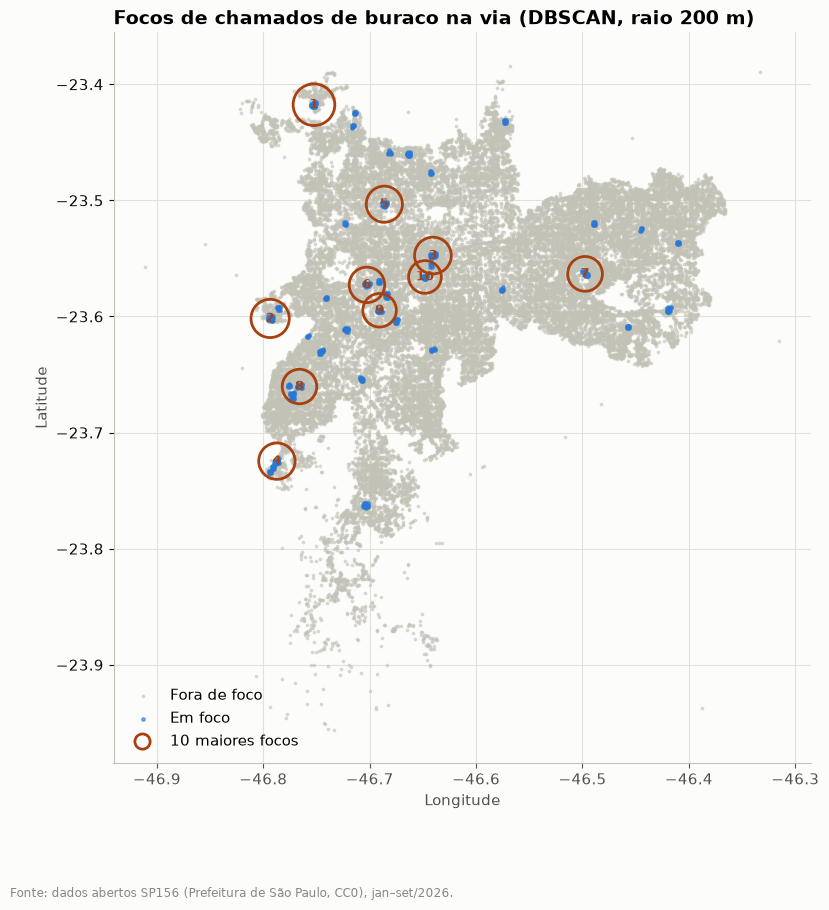

In [13]:
fig, ax = plt.subplots(figsize=(9, 9.5))
ruido = pontos[pontos['foco'] < 0]
ax.scatter(ruido['lon'], ruido['lat'], s=3, color=COR['eixo'], alpha=.5, label='Fora de foco', rasterized=True)
dentro = pontos[pontos['foco'] >= 0]
ax.scatter(dentro['lon'], dentro['lat'], s=6, color=COR['serie'], alpha=.6, label='Em foco', rasterized=True)
top = focos.head(10)
ax.scatter(top['lon'], top['lat'], s=top['chamados'] / top['chamados'].max() * 900, facecolor='none',
           edgecolor=COR['alerta'], linewidth=2, label='10 maiores focos')
for i, (_, f) in enumerate(top.iterrows(), start=1):
    ax.annotate(str(i), (f['lon'], f['lat']), ha='center', va='center', fontsize=9, weight='bold', color=COR['alerta'])
ax.set_aspect(1 / np.cos(np.radians(-23.6))); ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude')
leg = ax.legend(loc='lower left', markerscale=1)
for h in leg.legend_handles[-1:]:
    h.set_sizes([120])                                   # círculo da legenda em tamanho legível
ax.set_title('Focos de chamados de buraco na via (DBSCAN, raio 200 m)')
salvar(fig, '05_focos_buraco.png')

---
## 4. Detecção de anomalias

### 4.1 Dias atípicos de volume

Comparamos cada dia com o **esperado para aquele dia da semana** (mediana móvel das 4 semanas
anteriores) e aplicamos dois detectores:

- **z-score robusto** (mediana e MAD) sobre a razão real/esperado — regra simples e explicável;
- **Isolation Forest** sobre a razão de cada serviço — capta dias com **mistura** de serviços incomum.

Validamos contra o **calendário de feriados** de São Paulo em 2026.

In [14]:
FERIADOS = {'2026-01-01': 'Confraternização', '2026-01-25': 'Aniversário de SP', '2026-02-16': 'Carnaval',
            '2026-02-17': 'Carnaval', '2026-04-03': 'Sexta-feira Santa', '2026-04-21': 'Tiradentes',
            '2026-05-01': 'Dia do Trabalho', '2026-06-04': 'Corpus Christi', '2026-07-09': 'Revolução Constitucionalista',
            '2026-09-07': 'Independência'}
v = volume.asfreq('D', fill_value=0)
esperado = v.groupby(v.index.dayofweek).transform(lambda s: s.shift(1).rolling(4, min_periods=2).median())
razao = (v / esperado.replace(0, np.nan)).iloc[28:]                      # descarta o início sem histórico
r = np.log(razao['total'])
z = (r - r.median()) / (1.4826 * (r - r.median()).abs().median())
iso = IsolationForest(n_estimators=300, contamination=.04, random_state=SEMENTE)
X_iso = np.log(razao.drop(columns='total').clip(lower=.05).fillna(1))
razao['anomalia_iso'] = iso.fit_predict(X_iso) == -1
razao['z'] = z
razao['anomalia_z'] = z.abs() > 3.5
anom = razao[razao['anomalia_z'] | razao['anomalia_iso']].copy()
anom['feriado'] = [FERIADOS.get(d.strftime('%Y-%m-%d'), '') for d in anom.index]
anom['volume'] = v.loc[anom.index, 'total']
anom['esperado'] = esperado.loc[anom.index, 'total'].round()
fer_no_periodo = [d for d in FERIADOS if pd.Timestamp(d) in razao.index]
achados = [d for d in fer_no_periodo if pd.Timestamp(d) in anom.index]
METRICAS['anomalias'] = {'dias_analisados': len(razao), 'dias_anomalos': len(anom),
                         'feriados_no_periodo': len(fer_no_periodo), 'feriados_detectados': len(achados),
                         'concordancia_z_iso': int((anom['anomalia_z'] & anom['anomalia_iso']).sum())}
print(f'{len(anom)} dias anômalos em {len(razao)} · feriados detectados: {len(achados)} de {len(fer_no_periodo)}')
anom[['volume', 'esperado', 'z', 'anomalia_z', 'anomalia_iso', 'feriado']].round(2)

C:\Users\jefferson.peixoto\AppData\Local\Temp\ipykernel_33676\1942068065.py:6: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  esperado = v.groupby(v.index.dayofweek).transform(lambda s: s.shift(1).rolling(4, min_periods=2).median())


19 dias anômalos em 245 · feriados detectados: 8 de 8


,volume,esperado,z,anomalia_z,anomalia_iso,feriado
data,,,,,,
2026-01-31,3376,4506.0,-3.58,True,False,
2026-02-16,5382,8170.0,-5.28,True,False,Carnaval
2026-02-17,5084,8070.0,-5.87,True,False,Carnaval
2026-04-03,3159,6560.0,-9.42,True,True,Sexta-feira Santa
2026-04-20,4817,7543.0,-5.69,True,False,
2026-04-21,3592,7445.0,-9.40,True,True,Tiradentes
2026-05-01,2947,6082.0,-9.34,True,True,Dia do Trabalho
2026-05-10,2210,3064.0,-4.08,True,True,
2026-05-23,2342,3116.0,-3.54,True,False,


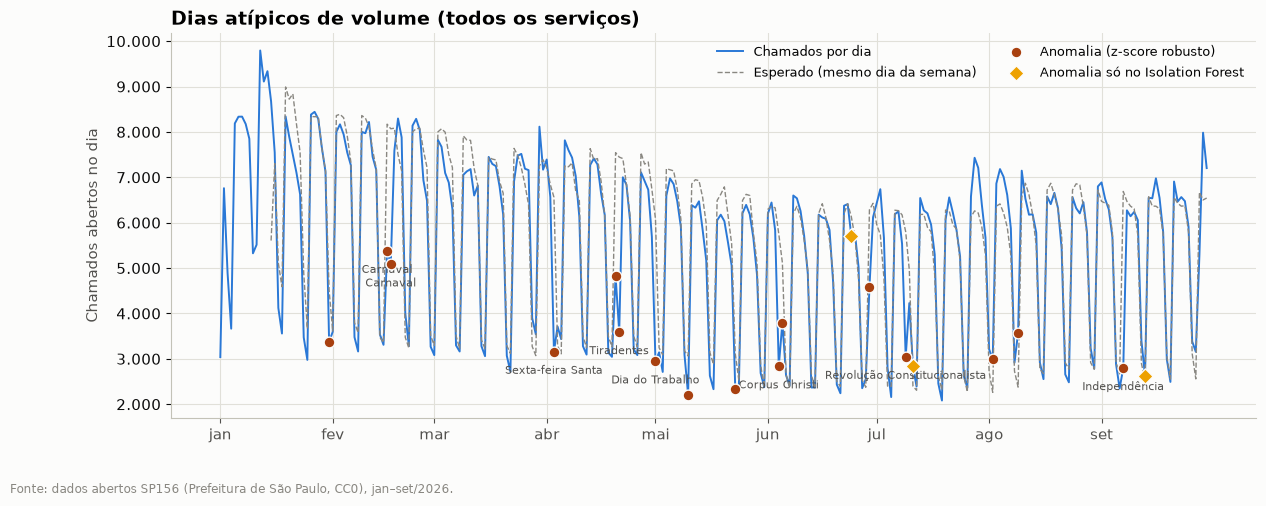

**Leitura:** os detectores marcaram **19 dias** e encontraram **8 dos 8 feriados** do período sem que o calendário fosse informado ao modelo — evidência de que estão captando o padrão real. Os dias anômalos que **não** são feriados merecem investigação (mutirões, chuvas, falhas de sistema).

In [15]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(v.index, v['total'], color=COR['serie'], lw=1.4, label='Chamados por dia')
ax.plot(esperado.index, esperado['total'], color=COR['mudo'], lw=1, ls='--', label='Esperado (mesmo dia da semana)')
for marca, filtro, cor, nome in [('o', anom['anomalia_z'], COR['alerta'], 'Anomalia (z-score robusto)'),
                                 ('D', anom['anomalia_iso'] & ~anom['anomalia_z'], '#eda100', 'Anomalia só no Isolation Forest')]:
    sel = anom[filtro]
    ax.scatter(sel.index, sel['volume'], marker=marca, s=60, color=cor, edgecolor=COR['fundo'], zorder=5, label=nome)
for d, row in anom[anom['feriado'] != ''].iterrows():
    ax.annotate(row['feriado'], (d, row['volume']), xytext=(0, -16), textcoords='offset points', ha='center', fontsize=8, color=COR['texto2'])
ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda x, _: br(f'{x:,.0f}')))
meses = pd.date_range(v.index.min(), v.index.max(), freq='MS')
ax.set_xticks(meses, ['jan', 'fev', 'mar', 'abr', 'mai', 'jun', 'jul', 'ago', 'set', 'out', 'nov', 'dez'][:len(meses)])
ax.set_ylabel('Chamados abertos no dia'); ax.legend(loc='upper right', ncols=2, fontsize=9.5)
ax.set_title('Dias atípicos de volume (todos os serviços)')
salvar(fig, '06_anomalias_volume.png')
display(Markdown(f"**Leitura:** os detectores marcaram **{len(anom)} dias** e encontraram **{len(achados)} dos {len(fer_no_periodo)} feriados** "
                 f"do período sem que o calendário fosse informado ao modelo — evidência de que estão captando o padrão real. "
                 f"Os dias anômalos que **não** são feriados merecem investigação (mutirões, chuvas, falhas de sistema)."))

### 4.2 Coordenadas suspeitas (qualidade de geocodificação)

Na Fase 4 encontramos um ponto com **73 registros no mesmo dia**. Aqui procuramos, para a base
inteira, coordenadas com padrão improvável para um problema real: muitos chamados, de **vários
serviços**, espalhados por **muitos dias**. Isso é típico de coordenada padrão (centroide) usada
quando o endereço não é geocodificado.

In [16]:
pts = base[base['lat'].notna()].groupby(['lat', 'lon']).agg(
    chamados=('servico', 'size'), servicos=('servico', 'nunique'), dias=('data_abertura', 'nunique'),
    max_no_dia=('apoios_proxy', 'max')).reset_index()
pts['max_no_dia'] += 1
F = np.log1p(pts[['chamados', 'servicos', 'dias', 'max_no_dia']])
iso_pt = IsolationForest(n_estimators=300, contamination=.001, random_state=SEMENTE).fit(F)
pts['score'] = -iso_pt.score_samples(F)
pts['suspeito'] = iso_pt.predict(F) == -1
suspeitos = pts[pts['suspeito']].sort_values('score', ascending=False)
METRICAS['anomalias'].update({'pontos_analisados': len(pts), 'pontos_suspeitos': len(suspeitos),
                              'chamados_em_pontos_suspeitos': int(suspeitos['chamados'].sum())})
print(f'{len(suspeitos)} coordenadas suspeitas de {len(pts):,} · {int(suspeitos["chamados"].sum()):,} chamados'.replace(',', '.'))
suspeitos.head(10)

62 coordenadas suspeitas de 61.136 · 4.167 chamados


,lat,lon,chamados,servicos,dias,max_no_dia,score,suspeito
8811,-23.668,-46.674,177,1,159,6,0.783220,True
23905,-23.590,-46.763,81,2,52,35,0.778992,True
31380,-23.563,-46.499,64,6,57,4,0.775760,True
23906,-23.590,-46.762,189,4,120,39,0.775338,True
19486,-23.606,-46.445,50,5,41,6,0.772033,True
22642,-23.595,-46.501,48,1,39,5,0.768176,True
5225,-23.699,-46.637,78,4,76,6,0.766990,True
46431,-23.509,-46.560,40,5,30,14,0.766827,True
40648,-23.531,-46.423,93,3,72,7,0.765971,True
17924,-23.612,-46.598,66,3,58,8,0.763729,True


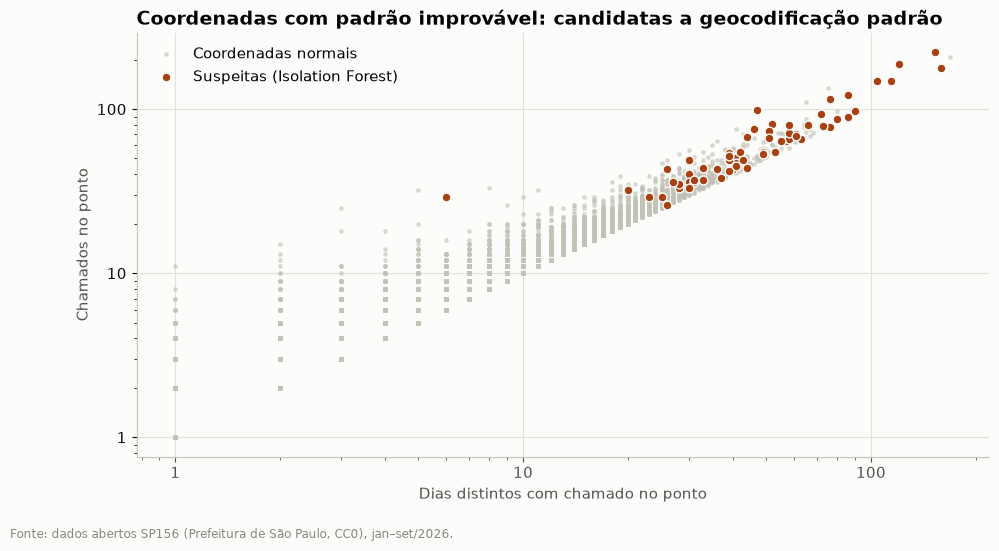

In [17]:
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.scatter(pts['dias'], pts['chamados'], s=6, color=COR['eixo'], alpha=.5, label='Coordenadas normais', rasterized=True)
ax.scatter(suspeitos['dias'], suspeitos['chamados'], s=40, color=COR['alerta'], edgecolor=COR['fundo'], label='Suspeitas (Isolation Forest)')
ax.set_xscale('log'); ax.set_yscale('log')
inteiro = matplotlib.ticker.FuncFormatter(lambda x, _: br(f'{x:,.0f}'))   # 1, 10, 100 em vez de 10⁰, 10¹, 10²
ax.xaxis.set_major_formatter(inteiro); ax.yaxis.set_major_formatter(inteiro)
ax.set_xlabel('Dias distintos com chamado no ponto'); ax.set_ylabel('Chamados no ponto')
ax.legend(loc='upper left'); ax.set_title('Coordenadas com padrão improvável: candidatas a geocodificação padrão')
salvar(fig, '07_anomalias_coordenadas.png')

---
## Conclusões

| Técnica | Resultado | Valor para o Cidade Alfa 156+ |
| --- | --- | --- |
| Regressão | erro menor que a regra "mediana do serviço" | prazo **estimado** mais realista para mostrar ao cidadão |
| Classificação | ranking de risco de atraso testado em período futuro | **alerta de prioridade** para a secretaria na abertura |
| Clusterização | perfis de subprefeituras e focos de buraco | metas e equipes por **perfil**, rotas para **focos** |
| Anomalias | feriados redescobertos sem calendário; coordenadas suspeitas | **monitoramento** de volume e **qualidade** da geocodificação |

**Limitações:** sem hora de abertura; sem protocolo (duplicatas sem local não confirmáveis);
regressão restrita aos resolvidos (censura); prazos são os do catálogo fictício da Cidade Alfa.

**Próximos passos:** levar o modelo de risco para a página da secretaria; recalibrar o prazo
exibido ao cidadão com a regressão; usar apoios reais (RN-03) no lugar das repetições.

In [18]:
Path('metricas.json').write_text(json.dumps(METRICAS, ensure_ascii=False, indent=1, default=str), encoding='utf-8')
print('Figuras:', sorted(p.name for p in FIGURAS.iterdir()))

Figuras: ['01_regressao.png', '02_regressao_importancia.png', '03_classificacao.png', '04_clusters_subprefeituras.png', '05_focos_buraco.png', '06_anomalias_volume.png', '07_anomalias_coordenadas.png']
